In [1]:
import torch
import os

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn transformers accelerate

In [3]:
from google.colab import files
import os

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print(filename)

Saving dev_sent_emo.csv to dev_sent_emo.csv
Saving test_sent_emo.csv to test_sent_emo.csv
Saving train_sent_emo.csv to train_sent_emo.csv

Uploaded files:
dev_sent_emo.csv
test_sent_emo.csv
train_sent_emo.csv


In [4]:
import pandas as pd
import os

# Load all three datasets
train_df = pd.read_csv("/content/train_sent_emo.csv")
dev_df = pd.read_csv("/content/dev_sent_emo.csv")
test_df = pd.read_csv("/content/test_sent_emo.csv")

# Display dataset information
print("MINDNEST - MELD DATASET")
print("-" * 40)

print("Training samples:", len(train_df))
print("Development samples:", len(dev_df))
print("Testing samples:", len(test_df))

print("\nTraining shape:", train_df.shape)
print("Development shape:", dev_df.shape)
print("Testing shape:", test_df.shape)

print("\nDataset columns:")
print(train_df.columns.tolist())

print("\nFirst five records:")
display(train_df.head())

MINDNEST - MELD DATASET
----------------------------------------
Training samples: 9989
Development samples: 1109
Testing samples: 2610

Training shape: (9989, 11)
Development shape: (1109, 11)
Testing shape: (2610, 11)

Dataset columns:
['Sr No.', 'Utterance', 'Speaker', 'Emotion', 'Sentiment', 'Dialogue_ID', 'Utterance_ID', 'Season', 'Episode', 'StartTime', 'EndTime']

First five records:


,Sr No.,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime
0,1,also I was the point person on my company’s tr...,Chandler,neutral,neutral,0,0,8,21,"00:16:16,059","00:16:21,731"
1,2,You must’ve had your hands full.,The Interviewer,neutral,neutral,0,1,8,21,"00:16:21,940","00:16:23,442"
2,3,That I did. That I did.,Chandler,neutral,neutral,0,2,8,21,"00:16:23,442","00:16:26,389"
3,4,So let’s talk a little bit about your duties.,The Interviewer,neutral,neutral,0,3,8,21,"00:16:26,820","00:16:29,572"
4,5,My duties? All right.,Chandler,surprise,positive,0,4,8,21,"00:16:34,452","00:16:40,917"


In [5]:
# Define emotion categories
emotion_labels = [
    "anger",
    "disgust",
    "fear",
    "joy",
    "neutral",
    "sadness",
    "surprise"
]

# Create label mapping
label_to_id = {
    emotion: index
    for index, emotion in enumerate(emotion_labels)
}

id_to_label = {
    index: emotion
    for emotion, index in label_to_id.items()
}

# Clean and encode labels
for df in [train_df, dev_df, test_df]:

    df["Emotion"] = (
        df["Emotion"]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    df["label"] = df["Emotion"].map(label_to_id)

# Verify
print("Emotion mapping:", label_to_id)

print("\nMissing labels:")
print("Training:", train_df["label"].isna().sum())
print("Development:", dev_df["label"].isna().sum())
print("Testing:", test_df["label"].isna().sum())

print("\nEmotion labels prepared successfully!")

Emotion mapping: {'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'neutral': 4, 'sadness': 5, 'surprise': 6}

Missing labels:
Training: 0
Development: 0
Testing: 0

Emotion labels prepared successfully!


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Prepare text
X_train = train_df["Utterance"].fillna("").astype(str)
y_train = train_df["label"].astype(int)

X_dev = dev_df["Utterance"].fillna("").astype(str)
y_dev = dev_df["label"].astype(int)

# TF-IDF feature extraction
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_dev_tfidf = tfidf.transform(X_dev)

print("TF-IDF feature extraction completed.")
print("Training features:", X_train_tfidf.shape)
print("Development features:", X_dev_tfidf.shape)

# Train baseline model
text_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    C=2.0,
    solver="lbfgs",
    random_state=42
)

text_model.fit(X_train_tfidf, y_train)

# Development predictions
dev_predictions = text_model.predict(X_dev_tfidf)

# Evaluate
baseline_accuracy = accuracy_score(y_dev, dev_predictions)
baseline_macro_f1 = f1_score(
    y_dev,
    dev_predictions,
    average="macro"
)

print("\nBASELINE RESULTS")
print("Development Accuracy:", round(baseline_accuracy * 100, 2), "%")
print("Development Macro F1:", round(baseline_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_dev,
    dev_predictions,
    labels=list(range(7)),
    target_names=emotion_labels,
    zero_division=0
))

TF-IDF feature extraction completed.
Training features: (9989, 10333)
Development features: (1109, 10333)

BASELINE RESULTS
Development Accuracy: 40.22 %
Development Macro F1: 0.3216

Classification Report:
              precision    recall  f1-score   support

       anger       0.25      0.26      0.25       153
     disgust       0.07      0.14      0.09        22
        fear       0.21      0.33      0.25        40
         joy       0.36      0.39      0.37       163
     neutral       0.59      0.47      0.52       470
     sadness       0.28      0.33      0.30       111
    surprise       0.44      0.47      0.46       150

    accuracy                           0.40      1109
   macro avg       0.31      0.34      0.32      1109
weighted avg       0.43      0.40      0.41      1109



In [7]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_NAME = "distilbert-base-uncased"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=7,
    id2label=id_to_label,
    label2id=label_to_id
)

model.to(device)

print("DistilBERT loaded successfully!")
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT loaded successfully!
Device: cuda
GPU: Tesla T4


In [8]:
import torch
from torch.utils.data import Dataset, DataLoader

MAX_LENGTH = 128
BATCH_SIZE = 16

class MELDDataset(Dataset):

    def __init__(self, dataframe, tokenizer):

        self.texts = dataframe["Utterance"].fillna("").astype(str).tolist()
        self.labels = dataframe["label"].astype(int).tolist()

        self.encodings = tokenizer(
            self.texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        return {
            "input_ids": self.encodings["input_ids"][index],
            "attention_mask": self.encodings["attention_mask"][index],
            "labels": torch.tensor(self.labels[index], dtype=torch.long)
        }


# Create datasets
train_dataset = MELDDataset(train_df, tokenizer)
dev_dataset = MELDDataset(dev_df, tokenizer)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DistilBERT datasets prepared successfully!")
print("Training samples:", len(train_dataset))
print("Development samples:", len(dev_dataset))
print("Training batches:", len(train_loader))
print("Development batches:", len(dev_loader))

DistilBERT datasets prepared successfully!
Training samples: 9989
Development samples: 1109
Training batches: 625
Development batches: 70


In [9]:
import torch
import numpy as np
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

EPOCHS = 3

best_macro_f1 = 0

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()

        total_loss += loss.item()

    # Development evaluation
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in dev_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            predictions = torch.argmax(
                outputs.logits, dim=1
            )

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(batch["labels"].numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(
        all_labels, all_predictions, average="macro"
    )

    avg_loss = total_loss / len(train_loader)

    print(f"\nEpoch: {epoch+1}/{EPOCHS}")
    print(f"Training Loss: {avg_loss:.4f}")
    print(f"Development Accuracy: {accuracy*100:.2f}%")
    print(f"Development Macro F1: {macro_f1:.4f}")

    # Save best model
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1

        model.save_pretrained("/content/best_distilbert")
        tokenizer.save_pretrained("/content/best_distilbert")

        print("Best model saved!")

Epoch 1:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch: 1/3
Training Loss: 1.2217
Development Accuracy: 60.05%
Development Macro F1: 0.3582


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!


Epoch 2:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch: 2/3
Training Loss: 1.0240
Development Accuracy: 59.15%
Development Macro F1: 0.3801


... (2 outputs left out)

Epoch 3:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch: 3/3
Training Loss: 0.8460
Development Accuracy: 58.97%
Development Macro F1: 0.3834


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DISTILBERT FINAL DEVELOPMENT REPORT
              precision    recall  f1-score   support

       anger       0.45      0.35      0.40       153
     disgust       0.33      0.05      0.08        22
        fear       0.29      0.05      0.09        40
         joy       0.47      0.54      0.50       163
     neutral       0.68      0.85      0.76       470
     sadness       0.44      0.23      0.30       111
    surprise       0.57      0.56      0.57       150

    accuracy                           0.59      1109
   macro avg       0.46      0.37      0.38      1109
weighted avg       0.56      0.59      0.56      1109



In [14]:
import torch
import torch.nn.functional as F
import numpy as np

from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

# Load the best previous model
model = AutoModelForSequenceClassification.from_pretrained(
    "/content/best_distilbert"
).to(device)

# Calculate class weights using training labels only
classes = np.arange(7)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

# Use square-root weights to avoid excessive weighting
class_weights = torch.tensor(
    np.sqrt(weights),
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=0.01
)

EPOCHS = 3
best_weighted_f1 = 0

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    for batch in tqdm(train_loader, desc=f"Weighted Epoch {epoch+1}"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = F.cross_entropy(
            outputs.logits,
            labels,
            weight=class_weights
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()
        total_loss += loss.item()

    # Development evaluation
    model.eval()
    predictions_all = []
    labels_all = []

    with torch.no_grad():

        for batch in dev_loader:

            outputs = model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device)
            )

            predictions = outputs.logits.argmax(dim=1)

            predictions_all.extend(predictions.cpu().numpy())
            labels_all.extend(batch["labels"].numpy())

    accuracy = accuracy_score(labels_all, predictions_all)

    macro_f1 = f1_score(
        labels_all,
        predictions_all,
        average="macro"
    )

    print(f"\nEpoch: {epoch+1}")
    print(f"Loss: {total_loss/len(train_loader):.4f}")
    print(f"Development Accuracy: {accuracy*100:.2f}%")
    print(f"Development Macro F1: {macro_f1:.4f}")

    if macro_f1 > best_weighted_f1:

        best_weighted_f1 = macro_f1

        model.save_pretrained("/content/best_weighted_distilbert")
        tokenizer.save_pretrained("/content/best_weighted_distilbert")

        print("Best weighted model saved!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Class weights: tensor([1.1343, 2.2947, 2.3075, 0.9048, 0.5504, 1.4454, 1.0882],
       device='cuda:0')


Weighted Epoch 1:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch: 1
Loss: 0.8111
Development Accuracy: 55.64%
Development Macro F1: 0.4173


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best weighted model saved!


... (2 outputs left out)

Weighted Epoch 3:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch: 3
Loss: 0.5137
Development Accuracy: 56.36%
Development Macro F1: 0.4280


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best weighted model saved!


In [15]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report, accuracy_score, f1_score
import torch

WEIGHTED_PATH = "/content/best_weighted_distilbert"

weighted_tokenizer = AutoTokenizer.from_pretrained(WEIGHTED_PATH)

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    WEIGHTED_PATH
).to(device)

weighted_model.eval()

weighted_predictions = []
weighted_labels = []

with torch.no_grad():

    for batch in dev_loader:

        outputs = weighted_model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device)
        )

        predictions = outputs.logits.argmax(dim=1)

        weighted_predictions.extend(predictions.cpu().numpy())
        weighted_labels.extend(batch["labels"].numpy())

print("WEIGHTED DISTILBERT REPORT")

print(classification_report(
    weighted_labels,
    weighted_predictions,
    target_names=emotion_labels,
    zero_division=0
))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

WEIGHTED DISTILBERT REPORT
              precision    recall  f1-score   support

       anger       0.42      0.34      0.37       153
     disgust       0.23      0.41      0.29        22
        fear       0.28      0.28      0.28        40
         joy       0.48      0.51      0.49       163
     neutral       0.72      0.75      0.73       470
     sadness       0.48      0.19      0.27       111
    surprise       0.49      0.63      0.56       150

    accuracy                           0.56      1109
   macro avg       0.44      0.44      0.43      1109
weighted avg       0.56      0.56      0.55      1109



In [17]:
import os

for item in os.listdir("/content"):
    path = os.path.join("/content", item)

    if os.path.isdir(path):
        print("FOLDER:", item)
        print("CONTENTS:", os.listdir(path)[:10])

FOLDER: .config
CONTENTS: ['.last_update_check.json', 'hidden_gcloud_config_universe_descriptor_data_cache_configs.db', 'config_sentinel', '.last_opt_in_prompt.yaml', 'default_configs.db', 'configurations', '.last_survey_prompt.yaml', 'gce', 'active_config', 'logs']
FOLDER: best_distilbert
CONTENTS: ['tokenizer_config.json', 'tokenizer.json', 'config.json', 'model.safetensors']
FOLDER: best_weighted_distilbert
CONTENTS: ['tokenizer_config.json', 'tokenizer.json', 'config.json', 'model.safetensors']
FOLDER: sample_data
CONTENTS: ['README.md', 'anscombe.json', 'california_housing_test.csv', 'mnist_train_small.csv', 'mnist_test.csv', 'california_housing_train.csv']


In [18]:
import shutil

total, used, free = shutil.disk_usage("/content")

print("Total Colab storage:", round(total / (1024**3), 2), "GB")
print("Used storage:", round(used / (1024**3), 2), "GB")
print("Free storage:", round(free / (1024**3), 2), "GB")

Total Colab storage: 112.64 GB
Used storage: 0.88 GB
Free storage: 111.74 GB


In [19]:
import os
import subprocess

archive_path = "/content/MELD.Raw.tar.gz"

url = "https://huggingface.co/datasets/declare-lab/MELD/resolve/main/MELD.Raw.tar.gz"

print("Starting MELD video dataset download...")

result = subprocess.run([
    "wget",
    "-c",
    "--show-progress",
    "-O", archive_path,
    url
])

if result.returncode == 0 and os.path.exists(archive_path):
    size_gb = os.path.getsize(archive_path) / (1024**3)
    print(f"\nDownload completed: {size_gb:.2f} GB")
else:
    print("Download incomplete. Please share the error.")

Starting MELD video dataset download...

Download completed: 10.13 GB


In [20]:
import tarfile
import os

archive_path = "/content/MELD.Raw.tar.gz"
extract_path = "/content/MELD_Videos"

os.makedirs(extract_path, exist_ok=True)

print("Extracting MELD video dataset...")

with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(path=extract_path)

print("\nExtraction completed!")

for root, dirs, files in os.walk(extract_path):
    video_files = [
        f for f in files
        if f.lower().endswith(".mp4")
    ]

    if video_files:
        print("Video folder:", root)
        print("Number of videos:", len(video_files))
        print("Examples:", video_files[:5])

Extracting MELD video dataset...


/tmp/ipykernel_449/156687178.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)



Extraction completed!


In [21]:
import os

EXTRACT_DIR = "/content/MELD_Videos"

video_count = 0

for root, dirs, files in os.walk(EXTRACT_DIR):
    videos = [f for f in files if f.lower().endswith(".mp4")]

    if videos:
        print("\nFolder:", root)
        print("Video count:", len(videos))
        print("First 5 videos:", videos[:5])

        video_count += len(videos)

print("\nTOTAL VIDEO FILES:", video_count)


TOTAL VIDEO FILES: 0


In [22]:
import os

EXTRACT_DIR = "/content/MELD_Videos"

print("Searching for nested video archives...\n")

for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        if file.endswith((".tar.gz", ".tgz")):
            path = os.path.join(root, file)
            size = os.path.getsize(path) / (1024**3)

            print("Archive:", file)
            print("Location:", path)
            print("Size:", round(size, 2), "GB")
            print("-" * 40)

Searching for nested video archives...

Archive: test.tar.gz
Location: /content/MELD_Videos/MELD.Raw/test.tar.gz
Size: 2.08 GB
----------------------------------------
Archive: dev.tar.gz
Location: /content/MELD_Videos/MELD.Raw/dev.tar.gz
Size: 0.72 GB
----------------------------------------
Archive: train.tar.gz
Location: /content/MELD_Videos/MELD.Raw/train.tar.gz
Size: 7.32 GB
----------------------------------------


In [23]:
import tarfile
import os

BASE_DIR = "/content/MELD_Videos/MELD.Raw"

archives = [
    "train.tar.gz",
    "dev.tar.gz",
    "test.tar.gz"
]

for archive in archives:
    archive_path = os.path.join(BASE_DIR, archive)

    print(f"\nExtracting {archive}...")

    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(path=BASE_DIR)

    print(f"{archive} extracted successfully!")

print("\nALL MELD VIDEO ARCHIVES EXTRACTED!")


Extracting train.tar.gz...


/tmp/ipykernel_449/1974869752.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=BASE_DIR)


train.tar.gz extracted successfully!

Extracting dev.tar.gz...
dev.tar.gz extracted successfully!

Extracting test.tar.gz...
test.tar.gz extracted successfully!

ALL MELD VIDEO ARCHIVES EXTRACTED!


In [24]:
import os

BASE_DIR = "/content/MELD_Videos/MELD.Raw"

for split in ["train", "dev", "test"]:
    split_dir = os.path.join(BASE_DIR, split)

    video_files = []

    for root, dirs, files in os.walk(split_dir):
        video_files.extend([
            f for f in files
            if f.lower().endswith(".mp4")
        ])

    print(f"\n{split.upper()} VIDEOS:", len(video_files))
    print("Examples:", video_files[:5])


TRAIN VIDEOS: 0
Examples: []

DEV VIDEOS: 0
Examples: []

TEST VIDEOS: 0
Examples: []


In [25]:
import os

BASE_DIR = "/content/MELD_Videos/MELD.Raw"

print("MAIN FOLDER CONTENTS:")
print(os.listdir(BASE_DIR))

print("\nSUBFOLDERS AND THEIR CONTENTS:")

for root, dirs, files in os.walk(BASE_DIR):
    level = root.replace(BASE_DIR, "").count(os.sep)

    if level <= 3:
        print("\nFolder:", root)
        print("Subfolders:", dirs[:10])
        print("Files:", files[:10])

MAIN FOLDER CONTENTS:
['train_sent_emo.csv', '._output_repeated_splits_test', 'output_repeated_splits_test', 'test.tar.gz', 'dev.tar.gz', 'README.txt', 'dev_splits_complete', '._train_splits', 'train.tar.gz', 'train_splits', 'dev_sent_emo.csv', 'test_sent_emo.csv']

SUBFOLDERS AND THEIR CONTENTS:

Folder: /content/MELD_Videos/MELD.Raw
Subfolders: ['output_repeated_splits_test', 'dev_splits_complete', 'train_splits']
Files: ['train_sent_emo.csv', '._output_repeated_splits_test', 'test.tar.gz', 'dev.tar.gz', 'README.txt', '._train_splits', 'train.tar.gz', 'dev_sent_emo.csv', 'test_sent_emo.csv']

Folder: /content/MELD_Videos/MELD.Raw/output_repeated_splits_test
Subfolders: []
Files: ['dia252_utt3.mp4', 'dia57_utt5.mp4', '._dia46_utt8.mp4', 'final_videos_testdia60_utt2.mp4', '._dia214_utt4.mp4', '._dia193_utt3.mp4', 'dia168_utt1.mp4', '._dia29_utt8.mp4', '._dia232_utt3.mp4', 'dia69_utt2.mp4']

Folder: /content/MELD_Videos/MELD.Raw/dev_splits_complete
Subfolders: []
Files: ['dia57_utt5.mp4

In [26]:
import os

BASE_DIR = "/content/MELD_Videos/MELD.Raw"

folders = {
    "Training": "train_splits",
    "Development": "dev_splits_complete",
    "Testing": "output_repeated_splits_test"
}

for split, folder in folders.items():

    folder_path = os.path.join(BASE_DIR, folder)

    videos = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(".mp4")
        and not f.startswith("._")
    ]

    print(f"\n{split} videos:", len(videos))
    print("Examples:", videos[:5])


Training videos: 9989
Examples: ['dia507_utt2.mp4', 'dia252_utt3.mp4', 'dia759_utt12.mp4', 'dia248_utt4.mp4', 'dia317_utt3.mp4']

Development videos: 1112
Examples: ['dia57_utt5.mp4', 'dia69_utt2.mp4', 'dia46_utt5.mp4', 'dia67_utt4.mp4', 'dia53_utt4.mp4']

Testing videos: 2747
Examples: ['dia252_utt3.mp4', 'dia57_utt5.mp4', 'final_videos_testdia60_utt2.mp4', 'dia168_utt1.mp4', 'dia69_utt2.mp4']


In [27]:
import os
import pandas as pd

BASE_DIR = "/content/MELD_Videos/MELD.Raw"

splits = {
    "train": {
        "folder": "train_splits",
        "csv": "/content/train_sent_emo.csv"
    },
    "dev": {
        "folder": "dev_splits_complete",
        "csv": "/content/dev_sent_emo.csv"
    },
    "test": {
        "folder": "output_repeated_splits_test",
        "csv": "/content/test_sent_emo.csv"
    }
}

for split, info in splits.items():

    df = pd.read_csv(info["csv"])

    folder = os.path.join(BASE_DIR, info["folder"])

    video_files = {
        f for f in os.listdir(folder)
        if f.lower().endswith(".mp4") and not f.startswith("._")
    }

    df["video_filename"] = df.apply(
        lambda row: f"dia{int(row['Dialogue_ID'])}_utt{int(row['Utterance_ID'])}.mp4",
        axis=1
    )

    matched = df["video_filename"].isin(video_files).sum()

    print(f"\n{split.upper()} MATCHING")
    print("CSV records:", len(df))
    print("Matching videos:", matched)
    print("Missing videos:", len(df) - matched)


TRAIN MATCHING
CSV records: 9989
Matching videos: 9989
Missing videos: 0

DEV MATCHING
CSV records: 1109
Matching videos: 1108
Missing videos: 1

TEST MATCHING
CSV records: 2610
Matching videos: 2610
Missing videos: 0


In [28]:
import os
import pandas as pd

BASE_DIR = "/content/MELD_Videos/MELD.Raw"

dev_df = pd.read_csv("/content/dev_sent_emo.csv")

dev_folder = os.path.join(BASE_DIR, "dev_splits_complete")

video_files = {
    f for f in os.listdir(dev_folder)
    if f.lower().endswith(".mp4") and not f.startswith("._")
}

dev_df["video_filename"] = dev_df.apply(
    lambda row: f"dia{int(row['Dialogue_ID'])}_utt{int(row['Utterance_ID'])}.mp4",
    axis=1
)

missing = dev_df[~dev_df["video_filename"].isin(video_files)]

print("Missing development record:")
print(missing[["Dialogue_ID", "Utterance_ID", "Utterance", "Emotion", "video_filename"]])

Missing development record:
      Dialogue_ID  Utterance_ID                    Utterance  Emotion  \
1084          110             7  Did they tell you anything?  neutral   

       video_filename  
1084  dia110_utt7.mp4  


In [29]:
import os
import pandas as pd

BASE_DIR = "/content/MELD_Videos/MELD.Raw"
OUTPUT_DIR = "/content/MindNest_Results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

splits = {
    "train": ("train_splits", "/content/train_sent_emo.csv"),
    "dev": ("dev_splits_complete", "/content/dev_sent_emo.csv"),
    "test": ("output_repeated_splits_test", "/content/test_sent_emo.csv")
}

for split, (folder, csv_path) in splits.items():

    df = pd.read_csv(csv_path)

    video_dir = os.path.join(BASE_DIR, folder)

    df["video_filename"] = df.apply(
        lambda row: f"dia{int(row['Dialogue_ID'])}_utt{int(row['Utterance_ID'])}.mp4",
        axis=1
    )

    df["video_path"] = df["video_filename"].apply(
        lambda filename: os.path.join(video_dir, filename)
    )

    matched_df = df[df["video_path"].apply(os.path.isfile)].copy()

    output_path = os.path.join(
        OUTPUT_DIR, f"{split}_matched.csv"
    )

    matched_df.to_csv(output_path, index=False)

    print(
        f"{split.upper()}: {len(matched_df)} matched records saved"
    )

print("\nMatched dataset preparation completed!")

TRAIN: 9989 matched records saved
DEV: 1108 matched records saved
TEST: 2610 matched records saved

Matched dataset preparation completed!


In [30]:
!pip install -q opencv-python-headless

import cv2

print("OpenCV version:", cv2.__version__)
print("Computer vision environment ready!")

OpenCV version: 4.14.0
Computer vision environment ready!


In [31]:
import cv2
import os

video_path = "/content/MELD_Videos/MELD.Raw/train_splits/dia507_utt2.mp4"

# Load OpenCV face detector
face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Unable to open video")
else:
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    print("Video opened successfully!")
    print("Total frames:", total_frames)
    print("FPS:", fps)

    faces_detected = 0

    # Test 5 frames
    for i in range(5):
        cap.set(cv2.CAP_PROP_POS_FRAMES, i * max(1, total_frames // 5))

        ret, frame = cap.read()

        if ret:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            faces = face_detector.detectMultiScale(
                gray,
                scaleFactor=1.1,
                minNeighbors=5,
                minSize=(30, 30)
            )

            faces_detected += len(faces)
            print(f"Frame {i+1}: {len(faces)} faces detected")

    cap.release()

    print("\nTotal faces detected across sampled frames:", faces_detected)

Video opened successfully!
Total frames: 33
FPS: 23.976042590949422
Frame 1: 1 faces detected
Frame 2: 1 faces detected
Frame 3: 1 faces detected
Frame 4: 1 faces detected
Frame 5: 1 faces detected

Total faces detected across sampled frames: 5


In [32]:
import cv2
import os

video_path = "/content/MELD_Videos/MELD.Raw/train_splits/dia507_utt2.mp4"

output_dir = "/content/MindNest_Results/sample_faces"
os.makedirs(output_dir, exist_ok=True)

detector = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

cap = cv2.VideoCapture(video_path)

saved_faces = 0
frame_number = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    # Process every 5th frame
    if frame_number % 5 == 0:

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        faces = detector.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(30, 30)
        )

        for (x, y, w, h) in faces:

            face = frame[y:y+h, x:x+w]

            face = cv2.resize(face, (224, 224))

            face_path = os.path.join(
                output_dir,
                f"face_{saved_faces}.jpg"
            )

            cv2.imwrite(face_path, face)

            saved_faces += 1

    frame_number += 1

cap.release()

print("Face extraction completed!")
print("Faces saved:", saved_faces)
print("Saved location:", output_dir)

Face extraction completed!
Faces saved: 6
Saved location: /content/MindNest_Results/sample_faces


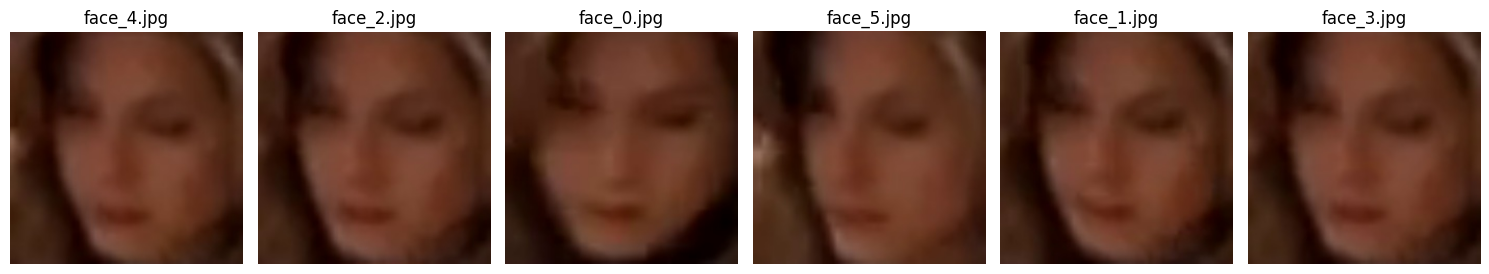

In [33]:
import os
import matplotlib.pyplot as plt
from PIL import Image

face_dir = "/content/MindNest_Results/sample_faces"

images = [
    f for f in os.listdir(face_dir)
    if f.endswith(".jpg")
]

plt.figure(figsize=(15, 5))

for i, filename in enumerate(images):
    img = Image.open(os.path.join(face_dir, filename))

    plt.subplot(1, len(images), i + 1)
    plt.imshow(img)
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

Improved faces saved: 8


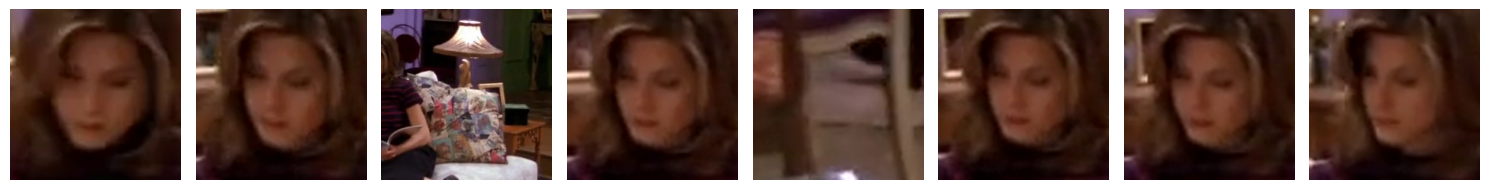

In [34]:
import cv2
import os
import matplotlib.pyplot as plt

video_path = "/content/MELD_Videos/MELD.Raw/train_splits/dia507_utt2.mp4"

output_dir = "/content/MindNest_Results/improved_faces"
os.makedirs(output_dir, exist_ok=True)

detector = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

cap = cv2.VideoCapture(video_path)

saved = 0
frame_no = 0
display_images = []

while True:
    ret, frame = cap.read()

    if not ret:
        break

    if frame_no % 5 == 0:

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        faces = detector.detectMultiScale(
            gray,
            scaleFactor=1.05,
            minNeighbors=4,
            minSize=(60, 60)
        )

        for (x, y, w, h) in faces:

            margin = int(0.20 * max(w, h))

            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(frame.shape[1], x + w + margin)
            y2 = min(frame.shape[0], y + h + margin)

            face = frame[y1:y2, x1:x2]

            if face.size == 0:
                continue

            face = cv2.resize(
                face, (224, 224),
                interpolation=cv2.INTER_CUBIC
            )

            path = os.path.join(
                output_dir, f"face_{saved}.jpg"
            )

            cv2.imwrite(path, face)
            display_images.append(cv2.cvtColor(face, cv2.COLOR_BGR2RGB))
            saved += 1

    frame_no += 1

cap.release()

print("Improved faces saved:", saved)

plt.figure(figsize=(15, 5))

for i, img in enumerate(display_images):
    plt.subplot(1, len(display_images), i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
import cv2

video_path = "/content/MELD_Videos/MELD.Raw/train_splits/dia507_utt2.mp4"

cap = cv2.VideoCapture(video_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("VIDEO QUALITY REPORT")
print("--------------------")
print("Resolution:", width, "x", height)
print("FPS:", round(fps, 2))
print("Total frames:", frames)

cap.release()

VIDEO QUALITY REPORT
--------------------
Resolution: 1280 x 720
FPS: 23.98
Total frames: 33


In [36]:
!pip install -q mediapipe

import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

video_path = "/content/MELD_Videos/MELD.Raw/train_splits/dia507_utt2.mp4"

mp_face = mp.solutions.face_detection

cap = cv2.VideoCapture(video_path)

face_images = []

with mp_face.FaceDetection(
    model_selection=1,
    min_detection_confidence=0.6
) as detector:

    frame_no = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        if frame_no % 5 == 0:

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            results = detector.process(rgb)

            if results.detections:
                h, w, _ = frame.shape

                for detection in results.detections:

                    box = detection.location_data.relative_bounding_box

                    x1 = max(0, int(box.xmin * w))
                    y1 = max(0, int(box.ymin * h))
                    x2 = min(w, int((box.xmin + box.width) * w))
                    y2 = min(h, int((box.ymin + box.height) * h))

                    face = frame[y1:y2, x1:x2]

                    if face.size > 0:
                        face = cv2.resize(face, (224, 224))
                        face_images.append(
                            cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
                        )

        frame_no += 1

cap.release()

print("MediaPipe faces detected:", len(face_images))

plt.figure(figsize=(15, 5))

for i, img in enumerate(face_images):
    plt.subplot(1, len(face_images), i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

AttributeError: module 'mediapipe' has no attribute 'solutions'

In [37]:
import mediapipe as mp

print("MediaPipe version:", mp.__version__)
print("MediaPipe location:", mp.__file__)
print("Has solutions:", hasattr(mp, "solutions"))

MediaPipe version: 1.2.3
MediaPipe location: /usr/local/lib/python3.13/dist-packages/mediapipe/__init__.py
Has solutions: False


In [38]:
import os
import urllib.request

MODEL_PATH = "/content/blaze_face_short_range.tflite"

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_detector/blaze_face_short_range/float16/1/"
    "blaze_face_short_range.tflite"
)

if not os.path.exists(MODEL_PATH):
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

print("Face detection model downloaded!")
print("Model exists:", os.path.exists(MODEL_PATH))
print("Model size:", round(os.path.getsize(MODEL_PATH) / 1024, 2), "KB")

Face detection model downloaded!
Model exists: True
Model size: 224.36 KB


In [39]:
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

MODEL_PATH = "/content/blaze_face_short_range.tflite"

# Create face detector
base_options = python.BaseOptions(
    model_asset_path=MODEL_PATH
)

options = vision.FaceDetectorOptions(
    base_options=base_options,
    min_detection_confidence=0.6
)

detector = vision.FaceDetector.create_from_options(options)

# Open sample video
video_path = "/content/MELD_Videos/MELD.Raw/train_splits/dia507_utt2.mp4"

cap = cv2.VideoCapture(video_path)

face_images = []
frame_no = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    if frame_no % 5 == 0:

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        results = detector.detect(mp_image)

        for detection in results.detections:

            box = detection.bounding_box

            x1 = max(0, box.origin_x)
            y1 = max(0, box.origin_y)
            x2 = min(frame.shape[1], x1 + box.width)
            y2 = min(frame.shape[0], y1 + box.height)

            face = frame[y1:y2, x1:x2]

            if face.size > 0:
                face = cv2.resize(face, (224, 224))
                face_images.append(
                    cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
                )

    frame_no += 1

cap.release()
detector.close()

print("BlazeFace detected faces:", len(face_images))

if face_images:
    plt.figure(figsize=(15, 5))

    for i, img in enumerate(face_images):
        plt.subplot(1, len(face_images), i + 1)
        plt.imshow(img)
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No faces detected in sampled frames.")

BlazeFace detected faces: 0
No faces detected in sampled frames.


Faces detected: 4
Confidence: 0.4659973680973053
Confidence: 0.42788392305374146
Confidence: 0.3153536319732666
Confidence: 0.3119576871395111


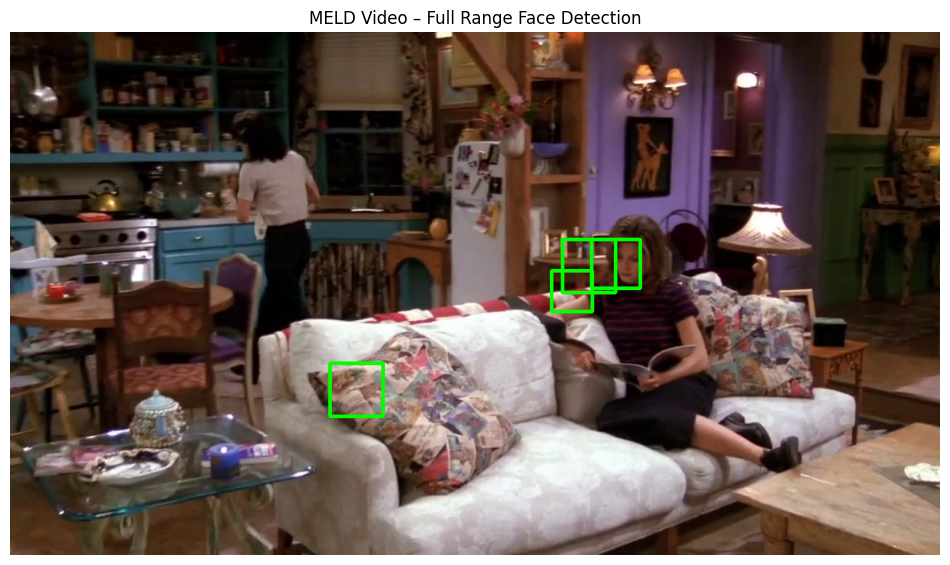

In [40]:
import os
import urllib.request
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Download full-range face detector
MODEL_PATH = "/content/blaze_face_full_range.tflite"

URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_detector/blaze_face_full_range/float16/1/"
    "blaze_face_full_range.tflite"
)

if not os.path.exists(MODEL_PATH):
    urllib.request.urlretrieve(URL, MODEL_PATH)

# Configure detector
base_options = python.BaseOptions(
    model_asset_path=MODEL_PATH
)

options = vision.FaceDetectorOptions(
    base_options=base_options,
    min_detection_confidence=0.3
)

detector = vision.FaceDetector.create_from_options(options)

# Read one video frame
video_path = "/content/MELD_Videos/MELD.Raw/train_splits/dia507_utt2.mp4"

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, 10)

ret, frame = cap.read()
cap.release()

if ret:
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    results = detector.detect(mp_image)

    print("Faces detected:", len(results.detections))

    # Draw detected faces
    for detection in results.detections:
        box = detection.bounding_box

        x, y = box.origin_x, box.origin_y
        w, h = box.width, box.height

        cv2.rectangle(
            rgb, (x, y), (x+w, y+h),
            (0, 255, 0), 3
        )

        print("Confidence:", detection.categories[0].score)

    plt.figure(figsize=(12, 7))
    plt.imshow(rgb)
    plt.axis("off")
    plt.title("MELD Video – Full Range Face Detection")
    plt.show()

else:
    print("Unable to read video frame.")

detector.close()

Faces detected: 2
Confidence: 0.466
Confidence: 0.428


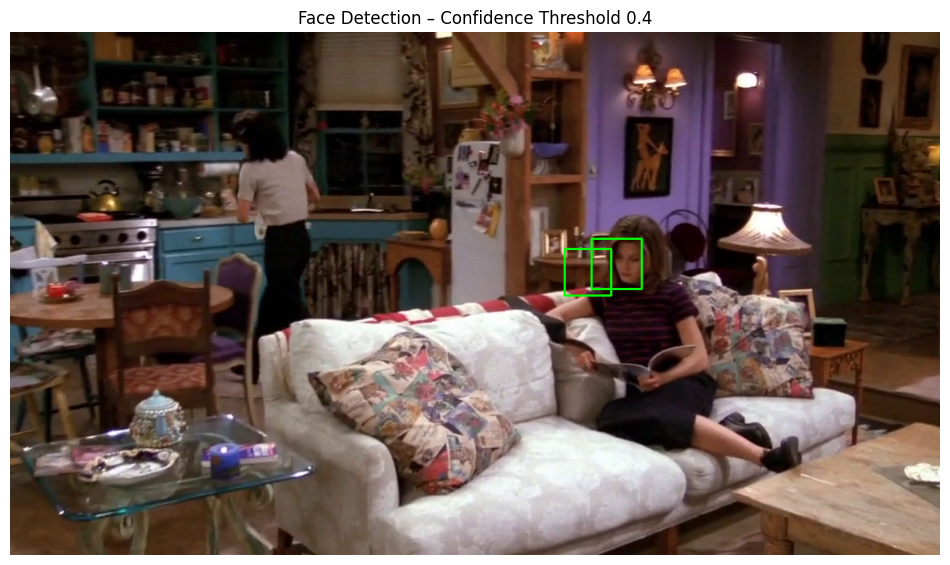

In [41]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

# Load Full Range detector with higher confidence
base_options = python.BaseOptions(
    model_asset_path="/content/blaze_face_full_range.tflite"
)

options = vision.FaceDetectorOptions(
    base_options=base_options,
    min_detection_confidence=0.4
)

detector = vision.FaceDetector.create_from_options(options)

# Read the sample video frame
video_path = "/content/MELD_Videos/MELD.Raw/train_splits/dia507_utt2.mp4"
cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, 10)

success, frame = cap.read()
cap.release()

if success:
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    results = detector.detect(mp_image)

    print("Faces detected:", len(results.detections))

    for detection in results.detections:
        print("Confidence:", round(detection.categories[0].score, 3))
        box = detection.bounding_box
        x, y, w, h = box.origin_x, box.origin_y, box.width, box.height
        cv2.rectangle(rgb, (x, y), (x+w, y+h), (0, 255, 0), 2)

    plt.figure(figsize=(12, 7))
    plt.imshow(rgb)
    plt.title("Face Detection – Confidence Threshold 0.4")
    plt.axis("off")
    plt.show()
else:
    print("Could not read video frame.")

In [42]:
import cv2

boxes = []
scores = []

for detection in results.detections:
    box = detection.bounding_box
    x, y = box.origin_x, box.origin_y
    w, h = box.width, box.height

    boxes.append([x, y, w, h])
    scores.append(float(detection.categories[0].score))

# Remove overlapping duplicate detections
indices = cv2.dnn.NMSBoxes(
    boxes,
    scores,
    score_threshold=0.4,
    nms_threshold=0.3
)

print("Faces after duplicate removal:", len(indices))

for i in indices:
    x, y, w, h = boxes[i]
    print("Confidence:", round(scores[i], 3))

Faces after duplicate removal: 2
Confidence: 0.466
Confidence: 0.428


Selected confidence: 0.466


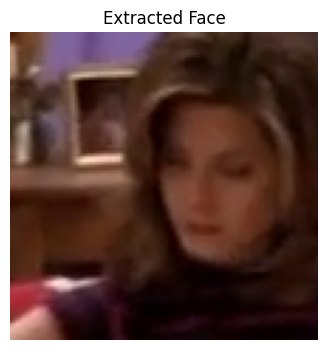

In [43]:
# Select the highest-confidence detection
best_index = max(range(len(scores)), key=lambda i: scores[i])

x, y, w, h = boxes[best_index]

# Add a small margin around the face
margin = 20
x1 = max(0, x - margin)
y1 = max(0, y - margin)
x2 = min(frame.shape[1], x + w + margin)
y2 = min(frame.shape[0], y + h + margin)

face_crop = frame[y1:y2, x1:x2]

print("Selected confidence:", round(scores[best_index], 3))

plt.figure(figsize=(4, 4))
plt.imshow(cv2.cvtColor(face_crop, cv2.COLOR_BGR2RGB))
plt.title("Extracted Face")
plt.axis("off")
plt.show()

In [44]:
import os
import cv2

video_folder = "/content/MELD_Videos/MELD.Raw/train_splits"

video_files = [
    f for f in os.listdir(video_folder)
    if f.endswith(".mp4") and not f.startswith("._")
]

print("Available videos:", len(video_files))
print("First 10 videos:")

for video in video_files[:10]:
    print(video)

Available videos: 9989
First 10 videos:
dia507_utt2.mp4
dia252_utt3.mp4
dia759_utt12.mp4
dia248_utt4.mp4
dia317_utt3.mp4
dia337_utt8.mp4
dia413_utt0.mp4
dia335_utt1.mp4
dia810_utt17.mp4
dia990_utt14.mp4


In [45]:
import os
import cv2
import mediapipe as mp
import pandas as pd

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

video_folder = "/content/MELD_Videos/MELD.Raw/train_splits"
output_folder = "/content/MindNest_Results/sample_faces_10"

os.makedirs(output_folder, exist_ok=True)

base_options = python.BaseOptions(
    model_asset_path="/content/blaze_face_full_range.tflite"
)

options = vision.FaceDetectorOptions(
    base_options=base_options,
    min_detection_confidence=0.4
)

detector = vision.FaceDetector.create_from_options(options)

results_list = []

for filename in video_files[:10]:

    video_path = os.path.join(video_folder, filename)
    cap = cv2.VideoCapture(video_path)

    # Read a frame near the middle of the video
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, total_frames // 2))

    success, frame = cap.read()
    cap.release()

    if not success:
        results_list.append({
            "video": filename,
            "face_detected": False
        })
        continue

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    detections = detector.detect(mp_image).detections

    if len(detections) > 0:

        best = max(
            detections,
            key=lambda d: d.categories[0].score
        )

        box = best.bounding_box

        x, y = box.origin_x, box.origin_y
        w, h = box.width, box.height

        margin = 20

        x1 = max(0, x - margin)
        y1 = max(0, y - margin)
        x2 = min(frame.shape[1], x + w + margin)
        y2 = min(frame.shape[0], y + h + margin)

        face = frame[y1:y2, x1:x2]

        if face.size > 0:
            save_path = os.path.join(
                output_folder,
                filename.replace(".mp4", ".jpg")
            )
            cv2.imwrite(save_path, face)

            results_list.append({
                "video": filename,
                "face_detected": True,
                "confidence": round(
                    best.categories[0].score, 3
                )
            })

    else:
        results_list.append({
            "video": filename,
            "face_detected": False
        })

results_df = pd.DataFrame(results_list)

display(results_df)
print("Successful face crops:", results_df["face_detected"].sum())

,video,face_detected,confidence
0,dia507_utt2.mp4,True,0.513
1,dia252_utt3.mp4,True,0.804
2,dia759_utt12.mp4,True,0.643
3,dia248_utt4.mp4,True,0.922
4,dia317_utt3.mp4,True,0.902
5,dia337_utt8.mp4,True,0.880
6,dia413_utt0.mp4,True,0.929
7,dia335_utt1.mp4,True,0.854
8,dia810_utt17.mp4,True,0.858
9,dia990_utt14.mp4,True,0.904


Successful face crops: 10


In [46]:
import os
import cv2
import mediapipe as mp
import pandas as pd

output_folder = "/content/MindNest_Results/sample_faces_100"
os.makedirs(output_folder, exist_ok=True)

results_100 = []

for filename in video_files[:100]:

    video_path = os.path.join(video_folder, filename)
    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, total_frames // 2))

    success, frame = cap.read()
    cap.release()

    detected = False
    confidence = None

    if success:
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        detections = detector.detect(mp_image).detections

        if detections:
            best = max(
                detections,
                key=lambda d: d.categories[0].score
            )

            box = best.bounding_box
            x, y = box.origin_x, box.origin_y
            w, h = box.width, box.height

            margin = 20
            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(frame.shape[1], x + w + margin)
            y2 = min(frame.shape[0], y + h + margin)

            face = frame[y1:y2, x1:x2]

            if face.size > 0:
                cv2.imwrite(
                    os.path.join(
                        output_folder,
                        filename.replace(".mp4", ".jpg")
                    ),
                    face
                )
                detected = True
                confidence = round(best.categories[0].score, 3)

    results_100.append({
        "video": filename,
        "face_detected": detected,
        "confidence": confidence
    })

df_100 = pd.DataFrame(results_100)

print("Videos tested:", len(df_100))
print("Successful detections:", df_100["face_detected"].sum())
print(
    "Detection rate:",
    round(df_100["face_detected"].mean() * 100, 2),
    "%"
)

display(df_100.head(15))

Videos tested: 100
Successful detections: 100
Detection rate: 100.0 %


,video,face_detected,confidence
0,dia507_utt2.mp4,True,0.513
1,dia252_utt3.mp4,True,0.804
2,dia759_utt12.mp4,True,0.643
3,dia248_utt4.mp4,True,0.922
4,dia317_utt3.mp4,True,0.902
5,dia337_utt8.mp4,True,0.880
6,dia413_utt0.mp4,True,0.929
7,dia335_utt1.mp4,True,0.854
8,dia810_utt17.mp4,True,0.858
9,dia990_utt14.mp4,True,0.904


In [47]:
import os
import cv2
import mediapipe as mp
import pandas as pd
from tqdm.notebook import tqdm

video_folder = "/content/MELD_Videos/MELD.Raw/train_splits"
output_folder = "/content/MindNest_Results/train_faces"

os.makedirs(output_folder, exist_ok=True)

extraction_results = []

for filename in tqdm(video_files, desc="Extracting training faces"):

    video_path = os.path.join(video_folder, filename)
    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        extraction_results.append({
            "video": filename,
            "face_detected": False,
            "confidence": None
        })
        continue

    cap.set(cv2.CAP_PROP_POS_FRAMES, total_frames // 2)
    success, frame = cap.read()
    cap.release()

    detected = False
    confidence = None

    if success:
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        detections = detector.detect(mp_image).detections

        if detections:
            best = max(
                detections,
                key=lambda d: d.categories[0].score
            )

            box = best.bounding_box
            x, y = box.origin_x, box.origin_y
            w, h = box.width, box.height

            margin = 20
            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(frame.shape[1], x + w + margin)
            y2 = min(frame.shape[0], y + h + margin)

            face = frame[y1:y2, x1:x2]

            if face.size > 0:
                save_path = os.path.join(
                    output_folder,
                    filename.replace(".mp4", ".jpg")
                )

                if cv2.imwrite(save_path, face):
                    detected = True
                    confidence = float(best.categories[0].score)

    extraction_results.append({
        "video": filename,
        "face_detected": detected,
        "confidence": confidence
    })

# Save extraction records
extraction_df = pd.DataFrame(extraction_results)

csv_path = "/content/MindNest_Results/train_face_extraction.csv"
extraction_df.to_csv(csv_path, index=False)

successful = int(extraction_df["face_detected"].sum())
total = len(extraction_df)

print("Total videos:", total)
print("Successful face crops:", successful)
print("Failed detections:", total - successful)
print("Detection rate:", round(successful / total * 100, 2), "%")
print("Results saved:", csv_path)

Extracting training faces:   0%|          | 0/9989 [00:00<?, ?it/s]

Total videos: 9989
Successful face crops: 9822
Failed detections: 167
Detection rate: 98.33 %
Results saved: /content/MindNest_Results/train_face_extraction.csv


In [48]:
import os
import cv2
import pandas as pd
from tqdm.notebook import tqdm

dev_df = pd.read_csv("/content/MindNest_Results/dev_matched.csv")

dev_video_folder = "/content/MELD_Videos/MELD.Raw/dev_splits_complete"
dev_face_folder = "/content/MindNest_Results/dev_faces"

os.makedirs(dev_face_folder, exist_ok=True)

dev_results = []

for filename in tqdm(dev_df["video_filename"], desc="Extracting dev faces"):

    video_path = os.path.join(dev_video_folder, filename)
    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    success = False
    confidence = None

    if total_frames > 0:
        cap.set(cv2.CAP_PROP_POS_FRAMES, total_frames // 2)
        success, frame = cap.read()

    cap.release()

    detected = False

    if success:
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        detections = detector.detect(mp_image).detections

        if detections:
            best = max(detections, key=lambda d: d.categories[0].score)
            box = best.bounding_box

            x, y, w, h = box.origin_x, box.origin_y, box.width, box.height
            margin = 20

            x1, y1 = max(0, x-margin), max(0, y-margin)
            x2 = min(frame.shape[1], x+w+margin)
            y2 = min(frame.shape[0], y+h+margin)

            face = frame[y1:y2, x1:x2]

            if face.size > 0:
                saved = cv2.imwrite(
                    os.path.join(dev_face_folder, filename.replace(".mp4", ".jpg")),
                    face
                )
                detected = bool(saved)
                confidence = float(best.categories[0].score) if saved else None

    dev_results.append({
        "video_filename": filename,
        "face_detected": detected,
        "confidence": confidence
    })

dev_extraction_df = pd.DataFrame(dev_results)
dev_extraction_df.to_csv(
    "/content/MindNest_Results/dev_face_extraction.csv",
    index=False
)

print("Development videos:", len(dev_extraction_df))
print("Successful crops:", int(dev_extraction_df["face_detected"].sum()))
print("Failed crops:", int((~dev_extraction_df["face_detected"]).sum()))

Extracting dev faces:   0%|          | 0/1108 [00:00<?, ?it/s]

Development videos: 1108
Successful crops: 1083
Failed crops: 25


In [49]:
import pandas as pd

train_data = pd.read_csv("/content/MindNest_Results/train_matched.csv")
dev_data = pd.read_csv("/content/MindNest_Results/dev_matched.csv")

print("Training columns:", train_data.columns.tolist())
print("Development columns:", dev_data.columns.tolist())

display(train_data[["video_filename", "Emotion"]].head())

Training columns: ['Sr No.', 'Utterance', 'Speaker', 'Emotion', 'Sentiment', 'Dialogue_ID', 'Utterance_ID', 'Season', 'Episode', 'StartTime', 'EndTime', 'video_filename', 'video_path']
Development columns: ['Sr No.', 'Utterance', 'Speaker', 'Emotion', 'Sentiment', 'Dialogue_ID', 'Utterance_ID', 'Season', 'Episode', 'StartTime', 'EndTime', 'video_filename', 'video_path']


,video_filename,Emotion
0,dia0_utt0.mp4,neutral
1,dia0_utt1.mp4,neutral
2,dia0_utt2.mp4,neutral
3,dia0_utt3.mp4,neutral
4,dia0_utt4.mp4,surprise


In [50]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing import image
from tqdm.notebook import tqdm

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(160, 160, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

# Prepare labels
emotion_labels = [
    "anger", "disgust", "fear",
    "joy", "neutral", "sadness", "surprise"
]

label_to_id = {
    emotion: i for i, emotion in enumerate(emotion_labels)
}

def extract_features(df, face_folder):

    features = []
    labels = []
    filenames = []

    for _, row in tqdm(df.iterrows(), total=len(df)):

        filename = row["video_filename"].replace(".mp4", ".jpg")
        img_path = os.path.join(face_folder, filename)

        if not os.path.exists(img_path):
            continue

        img = image.load_img(
            img_path,
            target_size=(160, 160)
        )

        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = preprocess_input(img_array)

        feature = base_model.predict(
            img_array, verbose=0
        )[0]

        emotion = str(row["Emotion"]).lower()

        if emotion not in label_to_id:
            continue

        features.append(feature)
        labels.append(label_to_id[emotion])
        filenames.append(row["video_filename"])

    return (
        np.array(features),
        np.array(labels),
        filenames
    )

# Extract training features
X_visual_train, y_visual_train, train_files = extract_features(
    train_data,
    "/content/MindNest_Results/train_faces"
)

print("Training feature shape:", X_visual_train.shape)
print("Training labels:", y_visual_train.shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


  0%|          | 0/9989 [00:00<?, ?it/s]

Training feature shape: (9822, 1280)
Training labels: (9822,)


In [51]:
X_visual_dev, y_visual_dev, dev_files = extract_features(
    dev_data,
    "/content/MindNest_Results/dev_faces"
)

print("Development feature shape:", X_visual_dev.shape)
print("Development labels:", y_visual_dev.shape)

  0%|          | 0/1108 [00:00<?, ?it/s]

Development feature shape: (1083, 1280)
Development labels: (1083,)


In [52]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import joblib
import os

visual_model = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=40,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

visual_model.fit(X_visual_train, y_visual_train)

visual_predictions = visual_model.predict(X_visual_dev)

visual_accuracy = accuracy_score(
    y_visual_dev, visual_predictions
)

visual_macro_f1 = f1_score(
    y_visual_dev, visual_predictions,
    average="macro"
)

print("Visual-only Accuracy:", round(visual_accuracy * 100, 2), "%")
print("Visual-only Macro F1:", round(visual_macro_f1, 4))

print(classification_report(
    y_visual_dev,
    visual_predictions,
    labels=list(range(7)),
    target_names=emotion_labels,
    zero_division=0
))

os.makedirs("/content/MindNest_Results/models", exist_ok=True)

joblib.dump(
    visual_model,
    "/content/MindNest_Results/models/visual_mobilenet_classifier.pkl"
)

Visual-only Accuracy: 42.66 %
Visual-only Macro F1: 0.0854
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00       151
     disgust       0.00      0.00      0.00        22
        fear       0.00      0.00      0.00        37
         joy       0.00      0.00      0.00       156
     neutral       0.43      1.00      0.60       462
     sadness       0.00      0.00      0.00       108
    surprise       0.00      0.00      0.00       147

    accuracy                           0.43      1083
   macro avg       0.06      0.14      0.09      1083
weighted avg       0.18      0.43      0.26      1083



['/content/MindNest_Results/models/visual_mobilenet_classifier.pkl']

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import joblib

visual_balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    C=0.1,
    random_state=42
)

visual_balanced_model.fit(
    X_visual_train,
    y_visual_train
)

visual_balanced_predictions = visual_balanced_model.predict(
    X_visual_dev
)

print(
    "Balanced Visual Accuracy:",
    round(accuracy_score(y_visual_dev, visual_balanced_predictions) * 100, 2),
    "%"
)

print(
    "Balanced Visual Macro F1:",
    round(f1_score(
        y_visual_dev,
        visual_balanced_predictions,
        average="macro"
    ), 4)
)

print(classification_report(
    y_visual_dev,
    visual_balanced_predictions,
    labels=list(range(7)),
    target_names=emotion_labels,
    zero_division=0
))

joblib.dump(
    visual_balanced_model,
    "/content/MindNest_Results/models/visual_balanced_classifier.pkl"
)

Balanced Visual Accuracy: 16.53 %
Balanced Visual Macro F1: 0.1367
              precision    recall  f1-score   support

       anger       0.17      0.20      0.18       151
     disgust       0.02      0.09      0.04        22
        fear       0.04      0.14      0.06        37
         joy       0.16      0.18      0.17       156
     neutral       0.41      0.16      0.23       462
     sadness       0.13      0.18      0.15       108
    surprise       0.11      0.15      0.13       147

    accuracy                           0.17      1083
   macro avg       0.15      0.16      0.14      1083
weighted avg       0.25      0.17      0.18      1083



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


['/content/MindNest_Results/models/visual_balanced_classifier.pkl']

In [54]:
import torch
import numpy as np
import pandas as pd
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import DataLoader, TensorDataset
from tqdm.notebook import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the saved DistilBERT model
tokenizer = AutoTokenizer.from_pretrained("/content/best_distilbert")
text_model = AutoModel.from_pretrained("/content/best_distilbert")
text_model.to(device)
text_model.eval()

def extract_text_embeddings(data, filenames, batch_size=32):

    lookup = data.set_index("video_filename")

    selected = lookup.loc[filenames]
    texts = selected["Utterance"].fillna("").astype(str).tolist()

    all_embeddings = []

    for start in tqdm(range(0, len(texts), batch_size)):
        batch_texts = texts[start:start + batch_size]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = text_model(**inputs)

        embeddings = outputs.last_hidden_state[:, 0, :]
        all_embeddings.append(embeddings.cpu().numpy())

    return np.concatenate(all_embeddings, axis=0)

# Extract embeddings in the same order as visual features
X_text_train = extract_text_embeddings(train_data, train_files)
X_text_dev = extract_text_embeddings(dev_data, dev_files)

print("Text training shape:", X_text_train.shape)
print("Text development shape:", X_text_dev.shape)
print("Visual training shape:", X_visual_train.shape)
print("Visual development shape:", X_visual_dev.shape)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: /content/best_distilbert
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.weight     | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/307 [00:00<?, ?it/s]

  0%|          | 0/34 [00:00<?, ?it/s]

Text training shape: (9822, 768)
Text development shape: (1083, 768)
Visual training shape: (9822, 1280)
Visual development shape: (1083, 1280)


In [55]:
import numpy as np
import joblib
import os

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Scale text and visual features separately
text_scaler = StandardScaler()
visual_scaler = StandardScaler()

X_text_train_scaled = text_scaler.fit_transform(X_text_train)
X_text_dev_scaled = text_scaler.transform(X_text_dev)

X_visual_train_scaled = visual_scaler.fit_transform(X_visual_train)
X_visual_dev_scaled = visual_scaler.transform(X_visual_dev)

# Combine both modalities
X_fusion_train = np.concatenate(
    [X_text_train_scaled, X_visual_train_scaled], axis=1
)

X_fusion_dev = np.concatenate(
    [X_text_dev_scaled, X_visual_dev_scaled], axis=1
)

print("Combined training shape:", X_fusion_train.shape)
print("Combined development shape:", X_fusion_dev.shape)

# Train multimodal classifier
fusion_model = LogisticRegression(
    max_iter=2000,
    C=0.1,
    class_weight=None,
    random_state=42
)

fusion_model.fit(X_fusion_train, y_visual_train)

# Evaluate
fusion_predictions = fusion_model.predict(X_fusion_dev)

fusion_accuracy = accuracy_score(
    y_visual_dev, fusion_predictions
)

fusion_macro_f1 = f1_score(
    y_visual_dev, fusion_predictions, average="macro"
)

print("\nMULTIMODAL MODEL RESULTS")
print("Accuracy:", round(fusion_accuracy * 100, 2), "%")
print("Macro F1:", round(fusion_macro_f1, 4))

print(classification_report(
    y_visual_dev,
    fusion_predictions,
    labels=list(range(7)),
    target_names=emotion_labels,
    zero_division=0
))

# Save model and scalers
os.makedirs("/content/MindNest_Results/models", exist_ok=True)

joblib.dump({
    "text_scaler": text_scaler,
    "visual_scaler": visual_scaler,
    "classifier": fusion_model,
    "emotion_labels": emotion_labels
}, "/content/MindNest_Results/models/multimodal_model.pkl")

print("Multimodal model saved successfully!")

Combined training shape: (9822, 2048)
Combined development shape: (1083, 2048)

MULTIMODAL MODEL RESULTS
Accuracy: 54.02 %
Macro F1: 0.3649
              precision    recall  f1-score   support

       anger       0.43      0.36      0.39       151
     disgust       0.17      0.14      0.15        22
        fear       0.08      0.05      0.07        37
         joy       0.42      0.49      0.46       156
     neutral       0.67      0.76      0.71       462
     sadness       0.33      0.20      0.25       108
    surprise       0.53      0.53      0.53       147

    accuracy                           0.54      1083
   macro avg       0.38      0.36      0.36      1083
weighted avg       0.52      0.54      0.53      1083

Multimodal model saved successfully!


In [56]:
import torch
import numpy as np
import pandas as pd

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.notebook import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reload the saved DistilBERT emotion classifier
tokenizer = AutoTokenizer.from_pretrained("/content/best_distilbert")

text_classifier = AutoModelForSequenceClassification.from_pretrained(
    "/content/best_distilbert"
).to(device)

text_classifier.eval()

# Select exactly the same development samples as multimodal
dev_lookup = dev_data.set_index("video_filename")
matched_dev = dev_lookup.loc[dev_files]

texts = matched_dev["Utterance"].fillna("").astype(str).tolist()
true_labels = np.array([
    label_to_id[str(e).lower()]
    for e in matched_dev["Emotion"]
])

predictions = []

for start in tqdm(range(0, len(texts), 32)):
    batch = texts[start:start + 32]

    inputs = tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        logits = text_classifier(**inputs).logits

    predictions.extend(
        torch.argmax(logits, dim=1).cpu().numpy()
    )

matched_accuracy = accuracy_score(true_labels, predictions)
matched_macro_f1 = f1_score(
    true_labels, predictions, average="macro"
)

print("Same-sample DistilBERT Accuracy:",
      round(matched_accuracy * 100, 2), "%")

print("Same-sample DistilBERT Macro F1:",
      round(matched_macro_f1, 4))

print(classification_report(
    true_labels,
    predictions,
    labels=list(range(7)),
    target_names=emotion_labels,
    zero_division=0
))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  0%|          | 0/34 [00:00<?, ?it/s]

Same-sample DistilBERT Accuracy: 59.46 %
Same-sample DistilBERT Macro F1: 0.3885
              precision    recall  f1-score   support

       anger       0.46      0.36      0.40       151
     disgust       0.33      0.05      0.08        22
        fear       0.33      0.05      0.09        37
         joy       0.47      0.55      0.51       156
     neutral       0.68      0.85      0.76       462
     sadness       0.44      0.23      0.30       108
    surprise       0.58      0.56      0.57       147

    accuracy                           0.59      1083
   macro avg       0.47      0.38      0.39      1083
weighted avg       0.56      0.59      0.57      1083



,Model,Accuracy (%),Macro F1
0,DistilBERT Text-only,59.46,0.3885
1,MobileNetV2 Visual-only,42.66,0.0854
2,Balanced Visual-only,16.53,0.1367
3,Multimodal (Text + Visual),54.02,0.3649


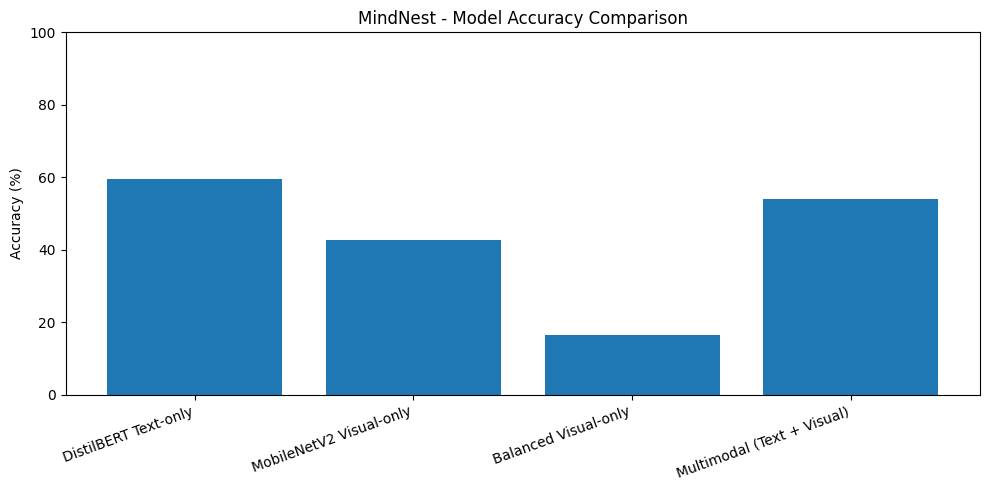

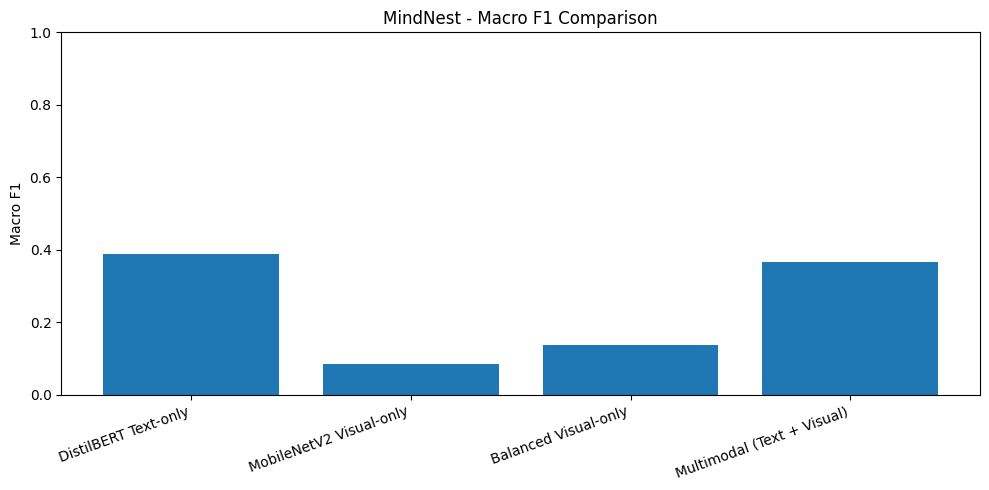

Comparison CSV and graphs saved successfully!


In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import os

results_folder = "/content/MindNest_Results"
os.makedirs(results_folder, exist_ok=True)

comparison = pd.DataFrame({
    "Model": [
        "DistilBERT Text-only",
        "MobileNetV2 Visual-only",
        "Balanced Visual-only",
        "Multimodal (Text + Visual)"
    ],
    "Accuracy (%)": [
        59.46, 42.66, 16.53, 54.02
    ],
    "Macro F1": [
        0.3885, 0.0854, 0.1367, 0.3649
    ]
})

comparison.to_csv(
    f"{results_folder}/final_model_comparison.csv",
    index=False
)

display(comparison)

# Accuracy graph
plt.figure(figsize=(10, 5))
plt.bar(comparison["Model"], comparison["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("MindNest - Model Accuracy Comparison")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(f"{results_folder}/accuracy_comparison.png", dpi=300)
plt.show()

# Macro F1 graph
plt.figure(figsize=(10, 5))
plt.bar(comparison["Model"], comparison["Macro F1"])
plt.ylabel("Macro F1")
plt.title("MindNest - Macro F1 Comparison")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(f"{results_folder}/macro_f1_comparison.png", dpi=300)
plt.show()

print("Comparison CSV and graphs saved successfully!")

In [58]:
print("Current model:", "/content/best_distilbert")
print("Training samples:", len(train_df))
print("Development samples:", len(dev_df))
print("Current best matched accuracy:", 59.46)
print("Current best matched Macro F1:", 0.3885)

print("\nAvailable GPU:")
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Current model: /content/best_distilbert
Training samples: 9989
Development samples: 1108
Current best matched accuracy: 59.46
Current best matched Macro F1: 0.3885

Available GPU:
Tesla T4


In [59]:
import os
import copy
import torch
import numpy as np
import pandas as pd

from torch.utils.data import TensorDataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.metrics import accuracy_score, f1_score
from tqdm.notebook import tqdm

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load existing model and tokenizer
model_path = "/content/best_distilbert"

tokenizer = AutoTokenizer.from_pretrained(model_path)

model = AutoModelForSequenceClassification.from_pretrained(
    model_path
).to(device)

# Prepare training data
train_texts = train_data["Utterance"].fillna("").astype(str).tolist()

train_labels = np.array([
    label_to_id[str(x).lower()]
    for x in train_data["Emotion"]
])

# Use exactly the same development samples as multimodal
matched_dev = dev_data.set_index("video_filename").loc[dev_files]

dev_texts = matched_dev["Utterance"].fillna("").astype(str).tolist()

dev_labels = np.array([
    label_to_id[str(x).lower()]
    for x in matched_dev["Emotion"]
])

# Tokenize
train_tokens = tokenizer(
    train_texts,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt"
)

dev_tokens = tokenizer(
    dev_texts,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt"
)

train_dataset = TensorDataset(
    train_tokens["input_ids"],
    train_tokens["attention_mask"],
    torch.tensor(train_labels, dtype=torch.long)
)

dev_dataset = TensorDataset(
    dev_tokens["input_ids"],
    dev_tokens["attention_mask"],
    torch.tensor(dev_labels, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=32,
    shuffle=False
)

# Optimizer and scheduler
epochs = 2
learning_rate = 1e-5

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=0.01
)

total_steps = len(train_loader) * epochs

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

best_accuracy = 0
best_macro_f1 = 0
best_state = None

# Training and evaluation
for epoch in range(epochs):

    model.train()
    total_loss = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}")

    for batch in progress:

        input_ids, attention_mask, labels = [
            x.to(device) for x in batch
        ]

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    # Development evaluation
    model.eval()
    predictions = []
    actual = []

    with torch.no_grad():
        for batch in dev_loader:

            input_ids, attention_mask, labels = [
                x.to(device) for x in batch
            ]

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            predictions.extend(
                torch.argmax(outputs.logits, dim=1).cpu().numpy()
            )

            actual.extend(labels.cpu().numpy())

    accuracy = accuracy_score(actual, predictions)
    macro_f1 = f1_score(
        actual, predictions, average="macro"
    )

    print(f"\nEpoch {epoch+1}")
    print("Training loss:", round(total_loss / len(train_loader), 4))
    print("Development accuracy:", round(accuracy * 100, 2), "%")
    print("Development Macro F1:", round(macro_f1, 4))

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_macro_f1 = macro_f1
        best_state = copy.deepcopy(model.state_dict())

# Save best model
if best_state is not None:

    model.load_state_dict(best_state)

    output_path = "/content/MindNest_Results/models/improved_distilbert"

    os.makedirs(output_path, exist_ok=True)

    model.save_pretrained(output_path)
    tokenizer.save_pretrained(output_path)

    print("\nBest improved accuracy:",
          round(best_accuracy * 100, 2), "%")

    print("Best Macro F1:", round(best_macro_f1, 4))
    print("Improved model saved:", output_path)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch 1
Training loss: 0.6132
Development accuracy: 59.28 %
Development Macro F1: 0.429


Epoch 2:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch 2
Training loss: 0.5116
Development accuracy: 58.63 %
Development Macro F1: 0.4246


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best improved accuracy: 59.28 %
Best Macro F1: 0.429
Improved model saved: /content/MindNest_Results/models/improved_distilbert


In [60]:
import pandas as pd

comparison = pd.DataFrame({
    "Sl. No.": [1, 2, 3, 4, 5],
    "Model": [
        "DistilBERT Text-only",
        "Improved DistilBERT",
        "MobileNetV2 Visual-only",
        "Balanced Visual-only",
        "Multimodal (Text + Visual)"
    ],
    "Accuracy (%)": [59.46, 59.28, 42.66, 16.53, 54.02],
    "Macro F1": [0.3885, 0.4290, 0.0854, 0.1367, 0.3649]
})

display(
    comparison.style
    .set_caption("MindNest – Comparative Model Performance")
    .format({
        "Accuracy (%)": "{:.2f}%",
        "Macro F1": "{:.4f}"
    })
    .highlight_max(
        subset=["Accuracy (%)", "Macro F1"],
        color="lightgreen"
    )
    .hide(axis="index")
)

comparison.to_csv(
    "/content/MindNest_Results/final_model_comparison.csv",
    index=False
)

print("Comparison table saved successfully!")

Sl. No.,Model,Accuracy (%),Macro F1
1,DistilBERT Text-only,59.46%,0.3885
2,Improved DistilBERT,59.28%,0.4290
3,MobileNetV2 Visual-only,42.66%,0.0854
4,Balanced Visual-only,16.53%,0.1367
5,Multimodal (Text + Visual),54.02%,0.3649


Comparison table saved successfully!
